In [2]:
!pip install -q kagglehub


In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "anthonytherrien/dog-vs-cat"
)

print("Dataset downloaded at:", path)

Using Colab cache for faster access to the 'dog-vs-cat' dataset.
Dataset downloaded at: /kaggle/input/dog-vs-cat


In [4]:
import os

for root, dirs, files in os.walk(path):
    print(root, "Images:", len(files))

/kaggle/input/dog-vs-cat Images: 0
/kaggle/input/dog-vs-cat/animals Images: 0
/kaggle/input/dog-vs-cat/animals/dog Images: 500
/kaggle/input/dog-vs-cat/animals/cat Images: 500


Using Colab cache for faster access to the 'dog-vs-cat' dataset.
Dataset downloaded at: /kaggle/input/dog-vs-cat
/kaggle/input/dog-vs-cat Images: 0
/kaggle/input/dog-vs-cat/animals Images: 0
/kaggle/input/dog-vs-cat/animals/dog Images: 500
/kaggle/input/dog-vs-cat/animals/cat Images: 500
Dataset directory: /kaggle/input/dog-vs-cat/animals
Found 1000 files belonging to 2 classes.
Using 800 files for training.
Found 1000 files belonging to 2 classes.
Using 200 files for validation.
Classes: ['cat', 'dog']
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3
50/50 ━━━━━━━━━━━━━━━━━━━━ 218s 4s/step - accuracy: 0.9762 - loss: 0.0481 - val_accuracy: 0.9950 - val_loss: 0.0077
Epoch 2/3
50/50 ━━━━━━━━━━━━━━━━━━━━ 258s 4s/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 3/3
50/50 ━━━━━━━━━━━━━━━━━━━━ 208s 4s/step - accuracy: 1.0000 - loss: 6.0084e-04 - val_accuracy: 1.0000 - val_loss: 9.1696e-04
Feature Extraction Time: 738.73 seconds
Epoch 1/3
50/5

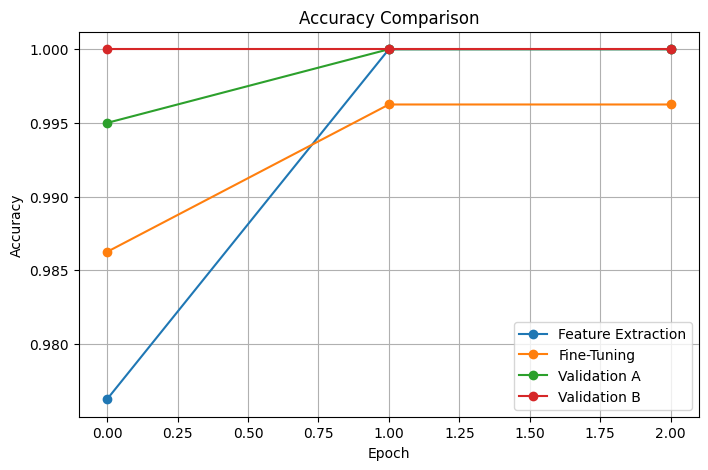

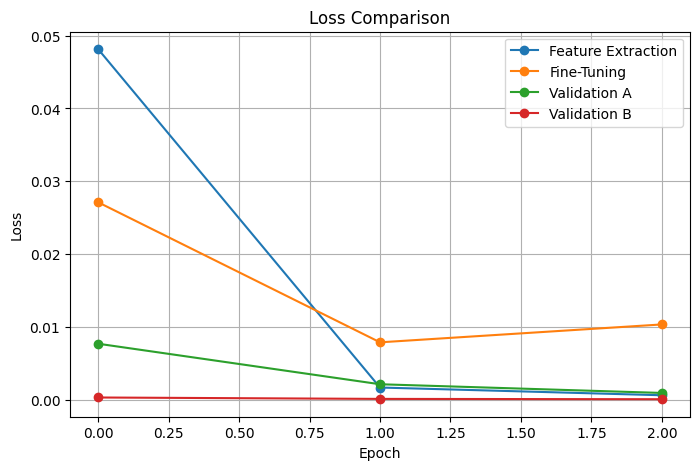

Model saved successfully!


In [5]:
# 1. Install KaggleHub
!pip install -q kagglehub

# 2. Import libraries
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import kagglehub
import os
import time

# 3. Download dataset from Kaggle
path = kagglehub.dataset_download(
    "anthonytherrien/dog-vs-cat"
)

print("Dataset downloaded at:", path)

# 4. Check dataset folders
for root, dirs, files in os.walk(path):
    print(root, "Images:", len(files))

# 5. Find directory containing cat and dog folders
data_dir = None

for root, dirs, files in os.walk(path):
    if len(dirs) >= 2:
        data_dir = root
        break

print("Dataset directory:", data_dir)

# 6. Load and split dataset
train = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=(224, 224),
    batch_size=16,
    validation_split=0.2,
    subset="training",
    seed=1
)

val = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=(224, 224),
    batch_size=16,
    validation_split=0.2,
    subset="validation",
    seed=1
)

print("Classes:", train.class_names)

# 7. Data augmentation
augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1)
])

# 8. Load pretrained ResNet50
base = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base.trainable = False

# 9. Create model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    augment,
    layers.Lambda(
        tf.keras.applications.resnet50.preprocess_input
    ),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

# 10. Experiment A: Feature Extraction
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

h1 = model.fit(
    train,
    validation_data=val,
    epochs=3
)

print("Feature Extraction Time:",
      round(time.time() - start, 2), "seconds")

# 11. Experiment B: Fine-Tuning
base.trainable = True

# Freeze all layers
for layer in base.layers:
    layer.trainable = False

# Unfreeze final convolutional block
for layer in base.layers:
    if "conv5_block" in layer.name:
        layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

h2 = model.fit(
    train,
    validation_data=val,
    epochs=3
)

print("Fine-Tuning Time:",
      round(time.time() - start, 2), "seconds")

# 12. Accuracy comparison
plt.figure(figsize=(8, 5))

plt.plot(h1.history["accuracy"], marker="o",
         label="Feature Extraction")

plt.plot(h2.history["accuracy"], marker="o",
         label="Fine-Tuning")

plt.plot(h1.history["val_accuracy"], marker="o",
         label="Validation A")

plt.plot(h2.history["val_accuracy"], marker="o",
         label="Validation B")

plt.title("Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# 13. Loss comparison
plt.figure(figsize=(8, 5))

plt.plot(h1.history["loss"], marker="o",
         label="Feature Extraction")

plt.plot(h2.history["loss"], marker="o",
         label="Fine-Tuning")

plt.plot(h1.history["val_loss"], marker="o",
         label="Validation A")

plt.plot(h2.history["val_loss"], marker="o",
         label="Validation B")

plt.title("Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# 14. Save model
model.save("cat_dog_model.keras")

print("Model saved successfully!")